# Portfolio Task 3 - COVID-19 Image Classification

**Objective:** develop and compare image classifiers, progressing from traditional ML
baselines in **Part A** to convolutional neural networks in **Part B**.
The dataset contains three chest X-ray classes: Covid, Normal, and Viral Pneumonia.

**Current status:** Part A is implemented and executed. Part B has an outline only;
its CNN code and experiments will be added later. LSTM and Part E are excluded.

## Notebook outline

1. [Environment, CUDA check, and baseline settings](#environment-and-configuration)
2. [Part A - Traditional machine learning](#part-a)
   - A.1 Load and analyse the dataset
   - A.2 Prepare image features and scaling
   - A.3 Train Random Forest and PyTorch MLP classifiers
   - A.4 Evaluate and compare the baselines
   - A.5 Visualise and interpret the results
   - Save Part A reproducibility artifacts
3. [Part B - CNN image classification](#part-b) *(planned)*
   - B.1 Load and prepare image data
   - B.2 Build and configure CNN variants
   - B.3 Train and validate the CNNs
   - B.4 Evaluate CNNs and compare with Part A
   - B.5 Save trained models and training histories
4. [Method references](#method-references)

<a id="environment-and-configuration"></a>
## Environment, CUDA check, and baseline settings

This notebook uses the existing **Conda environment `venv`** with Python 3.11.
Install the project dependencies from `requirements.txt` and register its kernel:

```powershell
conda activate venv
python -m pip install -r requirements.txt
python -m ipykernel install --sys-prefix --name venv --display-name "Python (conda venv)"
```

Select **Python (conda venv)** as the notebook kernel, then run the implemented cells
from top to bottom. CUDA availability is checked with a real tensor operation.
Random Forest runs on CPU; the PyTorch MLP and later CNNs use CUDA.

The configuration cell currently defines the agreed **Part A** settings: 64 x 64 grayscale
images, 300 trees, and an MLP with hidden layers (128, 64), Adam, batch size 32, and
80 epochs. These settings and the epoch budget are fixed before test evaluation.
CNN-specific settings will be defined in Part B when it is implemented.
Part A outputs are written to `artifacts/part_a/`.

In [1]:
import os

# Set this before CUDA is initialised to enable deterministic matrix multiplication.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import hashlib
import json
import random
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from torch import nn

SEED = 42
IMAGE_SIZE = (64, 64)
N_FOLDS = 5
RF_TREES = 300
MLP_HIDDEN_DIMS = (128, 64)
MLP_EPOCHS = 80
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
REQUIRE_CUDA = True  # Set False explicitly to allow a CPU-only MLP run.

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "data" / "Covid19-dataset").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project folder containing data/Covid19-dataset.")

DATA_DIR = PROJECT_ROOT / "data" / "Covid19-dataset"
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "part_a"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "models"
for directory in (FIGURE_DIR, TABLE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


seed_everything(SEED)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if REQUIRE_CUDA and DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA is required for this run. Select the CUDA-enabled conda venv kernel, "
        "or explicitly set REQUIRE_CUDA=False to run the MLP on CPU."
    )

# A real tensor operation verifies CUDA execution, beyond checking the driver.
probe = torch.ones((4, 4), device=DEVICE)
assert torch.allclose(probe @ probe, torch.full_like(probe, 4.0))
del probe

runtime_info = {
    "python_executable": sys.executable,
    "python_version": sys.version.split()[0],
    "environment": Path(sys.prefix).name,
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "pytorch_cuda_runtime": torch.version.cuda,
    "mlp_device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "random_forest_device": "cpu",
    "packages": {name: version(name) for name in (
        "numpy", "scipy", "scikit-learn", "pandas", "matplotlib", "Pillow",
        "joblib", "nbformat", "nbclient", "ipykernel",
    )},
}
display(pd.Series({key: value for key, value in runtime_info.items() if key != "packages"}, name="Runtime"))

python_executable       C:\Users\Admin\anaconda3\envs\venv\python.exe
python_version                                                3.11.15
environment                                                      venv
pytorch_version                                          2.11.0+cu128
cuda_available                                                   True
pytorch_cuda_runtime                                             12.8
mlp_device                                                     cuda:0
gpu_name                                   NVIDIA GeForce RTX 3070 Ti
random_forest_device                                              cpu
Name: Runtime, dtype: object

<a id="part-a"></a>
## Part A - Traditional Machine Learning Baselines

Compare **Random Forest** and a **PyTorch MLP Classifier** using the same flattened
grayscale image features. The MLP is a fully connected classification baseline
implemented in PyTorch for CUDA support; it is not scikit-learn's `MLPClassifier` estimator.
The workflow follows A.1-A.5 and establishes the reference results for the later CNNs.

### A.1 - Load and analyse the dataset

The target is the **categorical class folder**, so this is a three-class classification
problem. The supplied `train/` and `test/` folders already provide approximately an
80/20 split; their provenance is retained instead of reshuffling test images into training.
Every image is decoded to check readability. EXIF orientation is applied and all modes
are converted to grayscale consistently. Native grayscale pixels and dimensions form
a content hash for detecting exact duplicates before any model fitting.

In [2]:
CLASS_NAMES = sorted(path.name for path in (DATA_DIR / "train").iterdir() if path.is_dir())
test_class_names = sorted(path.name for path in (DATA_DIR / "test").iterdir() if path.is_dir())
if len(CLASS_NAMES) < 2 or CLASS_NAMES != test_class_names:
    raise ValueError("Train and test must contain the same two or more class folders.")
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def inspect_images(data_dir):
    records = []
    for split in ("train", "test"):
        for class_name in CLASS_NAMES:
            folder = data_dir / split / class_name
            paths = sorted(path for path in folder.rglob("*")
                           if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)
            if not paths:
                raise ValueError(f"No images found in {folder}.")
            for path in paths:
                try:
                    with Image.open(path) as image:
                        original_mode = image.mode
                        gray = ImageOps.exif_transpose(image).convert("L")
                        gray.load()
                        fingerprint = hashlib.sha256(
                            str(gray.size).encode("ascii") + gray.tobytes()
                        ).hexdigest()
                        records.append({
                            "relative_path": path.relative_to(data_dir).as_posix(),
                            "split": split,
                            "class_name": class_name,
                            "label": CLASS_TO_INDEX[class_name],
                            "width": gray.width,
                            "height": gray.height,
                            "original_mode": original_mode,
                            "pixel_hash": fingerprint,
                        })
                except (OSError, ValueError) as error:
                    raise ValueError(f"Cannot decode image: {path}") from error
    return pd.DataFrame(records).sort_values(["split", "relative_path"]).reset_index(drop=True)


raw_manifest = inspect_images(DATA_DIR)
original_counts = pd.crosstab(raw_manifest["class_name"], raw_manifest["split"])
display(original_counts.reindex(CLASS_NAMES)[["train", "test"]])
display(raw_manifest[["width", "height"]].describe().round(1))
display(raw_manifest["original_mode"].value_counts().rename("Image count").to_frame())
print(f"Original images: {len(raw_manifest)} | Classes: {len(CLASS_NAMES)}")
print(f"Target mapping: {CLASS_TO_INDEX}")

split,train,test
class_name,,
Covid,111,26
Normal,70,20
Viral Pneumonia,70,20


,width,height
count,317.0,317.0
mean,1624.6,1352.9
std,607.0,577.9
min,416.0,341.0
25%,1216.0,891.0
50%,1582.0,1319.0
75%,1980.0,1668.0
max,4248.0,4095.0


,Image count
original_mode,
RGB,267
L,42
RGBA,8


Original images: 317 | Classes: 3
Target mapping: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}


#### Duplicate audit and reproducible split

Within each split, retain the first path in sorted order for each native grayscale
pixel hash. If a hash occurs in both splits, exclude its training copy while preserving
the held-out test copy. Conflicting labels for identical images cause an error.
This audit uses image identity to prevent leakage; test outcomes never guide training.
Only manifests are filtered: **source images are not deleted or changed**.
Exact deduplication cannot establish patient-level independence because this dataset
does not supply patient identifiers.

,original_train,original_test,clean_train,clean_test
class_name,,,,
Covid,111,26,105,25
Normal,70,20,68,20
Viral Pneumonia,70,20,69,20


,relative_path,excluded_reason
20,test/Covid/auntminnie-2020_01_31_20_24_2322_20...,duplicate_within_split
113,train/Covid/069.jpg,training_image_also_in_test
139,train/Covid/COVID-00003b.jpg,training_image_also_in_test
148,train/Covid/COVID-00012.jpg,training_image_also_in_test
160,train/Covid/COVID-00022.jpg,training_image_also_in_test
171,train/Covid/COVID-00033.jpg,training_image_also_in_test
175,train/Covid/COVID-00037.jpg,training_image_also_in_test
189,train/Normal/020.jpeg,duplicate_within_split
243,train/Normal/094.jpeg,duplicate_within_split
256,train/Viral Pneumonia/020.jpeg,duplicate_within_split


Clean split: 242 train / 65 test (78.8% / 21.2%)


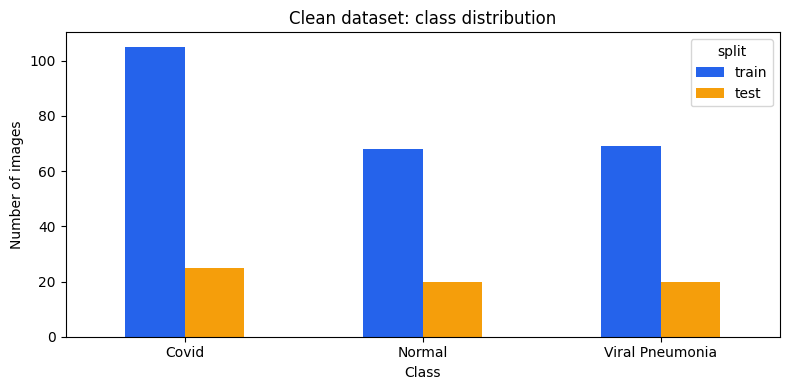

In [3]:
if raw_manifest.groupby("pixel_hash")["label"].nunique().gt(1).any():
    raise ValueError("Identical grayscale images have conflicting class labels.")

manifest = raw_manifest.copy()
manifest["excluded_reason"] = ""
within_split_duplicates = manifest.duplicated(["split", "pixel_hash"], keep="first")
manifest.loc[within_split_duplicates, "excluded_reason"] = "duplicate_within_split"
test_hashes = set(manifest.loc[manifest["split"].eq("test"), "pixel_hash"])
train_test_overlap = manifest["split"].eq("train") & manifest["pixel_hash"].isin(test_hashes)
manifest.loc[train_test_overlap, "excluded_reason"] = "training_image_also_in_test"
clean_manifest = manifest.loc[manifest["excluded_reason"].eq("")].copy()
excluded_manifest = manifest.loc[manifest["excluded_reason"].ne("")].copy()

train_manifest = clean_manifest.loc[clean_manifest["split"].eq("train")].reset_index(drop=True)
test_manifest = clean_manifest.loc[clean_manifest["split"].eq("test")].reset_index(drop=True)
assert set(train_manifest["pixel_hash"]).isdisjoint(test_manifest["pixel_hash"])
assert not clean_manifest.duplicated("pixel_hash").any()

clean_counts = pd.crosstab(clean_manifest["class_name"], clean_manifest["split"])
count_comparison = pd.DataFrame({
    "original_train": original_counts["train"],
    "original_test": original_counts["test"],
    "clean_train": clean_counts["train"],
    "clean_test": clean_counts["test"],
}).reindex(CLASS_NAMES)
display(count_comparison)
display(excluded_manifest[["relative_path", "excluded_reason"]])
train_fraction = len(train_manifest) / len(clean_manifest)
print(f"Clean split: {len(train_manifest)} train / {len(test_manifest)} test "
      f"({train_fraction:.1%} / {1 - train_fraction:.1%})")

manifest.to_csv(TABLE_DIR / "image_audit.csv", index=False)
clean_manifest.to_csv(TABLE_DIR / "clean_image_manifest.csv", index=False)
excluded_manifest.to_csv(TABLE_DIR / "excluded_duplicates.csv", index=False)
count_comparison.to_csv(TABLE_DIR / "class_distribution.csv")

fig, ax = plt.subplots(figsize=(8, 4))
clean_counts.reindex(CLASS_NAMES)[["train", "test"]].plot.bar(ax=ax, rot=0, color=["#2563eb", "#f59e0b"])
ax.set(title="Clean dataset: class distribution", xlabel="Class", ylabel="Number of images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

### A.2 — Prepare image features and scaling

Resize each grayscale image to 64×64 with bilinear interpolation, scale pixel intensities
to [0, 1], and flatten to **4,096 features**. Both baselines receive the same feature
representation; no pretrained feature extractor or augmentation is used.
Flattening removes explicit spatial structure, which motivates the later CNN comparison.
Resizing may distort aspect ratios and images may retain source-specific visual cues.

`StandardScaler` is fitted **inside each CV fold using only that fold's training rows**.
After CV, a separate scaler is fitted on all cleaned training rows for final refitting.
The same scaled arrays are passed to both classifiers. Trees do not need scaling,
but using it keeps the input pipeline consistent; the MLP benefits from standardisation.

X_train: (242, 4096), y_train: (242,)
X_test:  (65, 4096), y_test:  (65,)
Image representation: height=64, width=64, channels=1


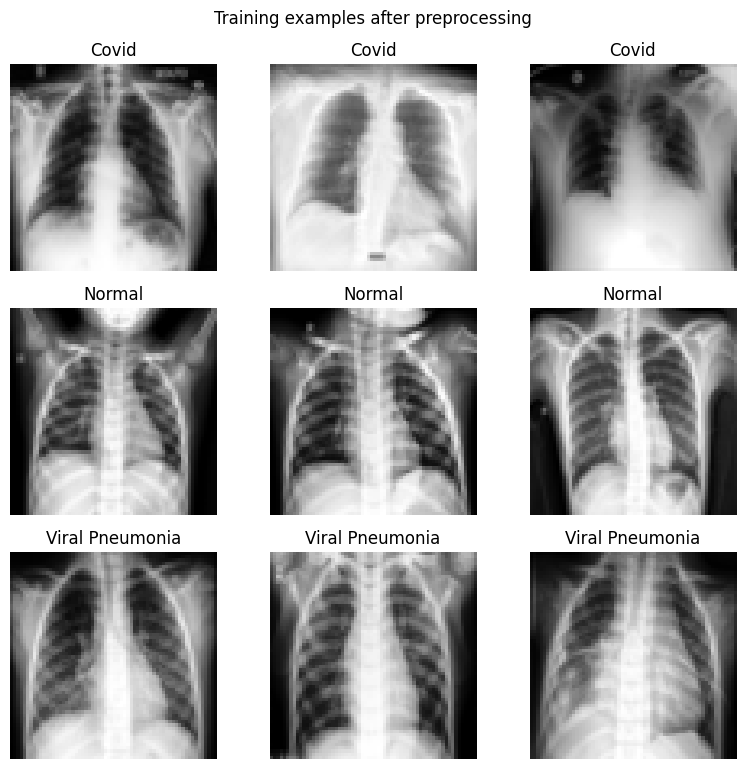

In [4]:
def load_pixel_features(image_manifest):
    features = []
    for relative_path in image_manifest["relative_path"]:
        with Image.open(DATA_DIR / relative_path) as image:
            gray = ImageOps.exif_transpose(image).convert("L")
            resized = gray.resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
            features.append(np.asarray(resized, dtype=np.float32).reshape(-1) / 255.0)
    return np.stack(features)


X_train = load_pixel_features(train_manifest)
X_test = load_pixel_features(test_manifest)
y_train = train_manifest["label"].to_numpy(dtype=np.int64)
y_test = test_manifest["label"].to_numpy(dtype=np.int64)

assert X_train.shape == (len(y_train), IMAGE_SIZE[0] * IMAGE_SIZE[1])
assert X_test.shape == (len(y_test), X_train.shape[1])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_test.min() <= X_test.max() <= 1

# Guard against additional identical inputs introduced by resizing.
train_feature_hashes = [hashlib.sha256(row.tobytes()).hexdigest() for row in X_train]
test_feature_hashes = [hashlib.sha256(row.tobytes()).hexdigest() for row in X_test]
assert len(set(train_feature_hashes)) == len(train_feature_hashes), "Repeated training features: review the audit."
assert len(set(test_feature_hashes)) == len(test_feature_hashes), "Repeated test features: review the audit."
assert set(train_feature_hashes).isdisjoint(test_feature_hashes), "Resized train/test inputs overlap."

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print(f"Image representation: height={IMAGE_SIZE[1]}, width={IMAGE_SIZE[0]}, channels=1")

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(8, 2.6 * len(CLASS_NAMES)), squeeze=False)
for label, class_name in enumerate(CLASS_NAMES):
    sample_indices = np.flatnonzero(y_train == label)[:3]
    for column, index in enumerate(sample_indices):
        axes[label, column].imshow(X_train[index].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap="gray")
        axes[label, column].set_title(class_name)
        axes[label, column].axis("off")
fig.suptitle("Training examples after preprocessing")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_examples.png", dpi=180, bbox_inches="tight")
plt.show()

### A.3 — Define and train the two classifiers

**Random Forest:** 300 trees, Gini criterion, square-root feature sampling, unrestricted
depth, fixed seed, and CPU parallelism capped at four workers.

**PyTorch MLP Classifier (128, 64):** Linear → ReLU → Linear → ReLU → Linear,
with three output logits. Cross-entropy consumes logits directly; softmax is not needed
before this loss. Use Adam, learning rate 0.001, L2 weight decay 0.0001, batch size 32,
and a fixed 80-epoch budget. There are no convolutional or recurrent layers.

All five folds use identical partitions for both models. Every fold constructs fresh
models and a fresh scaler. CV runs on training images only, sequentially for the GPU
MLP. No test metrics or test images are used for selecting hyperparameters or epochs.

In [5]:
RF_NAME = "Random Forest"
MLP_NAME = "PyTorch MLP (128, 64)"
MODEL_NAMES = [RF_NAME, MLP_NAME]


def make_random_forest(seed):
    return RandomForestClassifier(
        n_estimators=RF_TREES,
        criterion="gini",
        max_features="sqrt",
        random_state=seed,
        n_jobs=min(4, os.cpu_count() or 1),
    )


class MLPClassifier(nn.Module):
    """A fully connected classifier implemented with PyTorch, not sklearn."""

    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dims[0]),
            nn.ReLU(),
            nn.Linear(hidden_dims[0], hidden_dims[1]),
            nn.ReLU(),
            nn.Linear(hidden_dims[1], num_classes),
        )

    def forward(self, features):
        return self.layers(features)


def train_mlp(features, labels, seed):
    seed_everything(seed)
    model = MLPClassifier(features.shape[1], MLP_HIDDEN_DIMS, len(CLASS_NAMES)).to(DEVICE)
    feature_tensor = torch.as_tensor(features, dtype=torch.float32, device=DEVICE)
    label_tensor = torch.as_tensor(labels, dtype=torch.long, device=DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    history = []
    model.train()
    for epoch in range(1, MLP_EPOCHS + 1):
        epoch_loss = torch.zeros((), device=DEVICE)
        shuffled_indices = torch.randperm(len(labels), device=DEVICE)
        for batch_indices in shuffled_indices.split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(feature_tensor[batch_indices]), label_tensor[batch_indices])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.detach() * len(batch_indices)
        history.append({"epoch": epoch, "train_loss": epoch_loss.item() / len(labels)})
    assert all(parameter.device == DEVICE for parameter in model.parameters())
    return model, pd.DataFrame(history)


@torch.inference_mode()
def predict_mlp(model, features):
    model.eval()
    model_device = next(model.parameters()).device
    feature_tensor = torch.as_tensor(features, dtype=torch.float32, device=model_device)
    return model(feature_tensor).argmax(dim=1).cpu().numpy()


def classification_scores(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "weighted_f1": f1_score(labels, predictions, average="weighted", zero_division=0),
        "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0),
    }


class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
if class_counts.min() < N_FOLDS:
    raise ValueError("Every training class needs at least five samples for five-fold CV.")
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
fold_assignments = train_manifest[["relative_path", "class_name", "label", "pixel_hash"]].copy()
fold_assignments["validation_fold"] = -1
cv_records = []
oof_predictions = {name: np.full(len(y_train), -1, dtype=np.int64) for name in MODEL_NAMES}

for fold_number, (fit_indices, validation_indices) in enumerate(folds, start=1):
    fold_assignments.loc[validation_indices, "validation_fold"] = fold_number
    fold_scaler = StandardScaler()
    fold_train = fold_scaler.fit_transform(X_train[fit_indices]).astype(np.float32)
    fold_validation = fold_scaler.transform(X_train[validation_indices]).astype(np.float32)
    assert int(fold_scaler.n_samples_seen_) == len(fit_indices)
    for name in MODEL_NAMES:
        start = perf_counter()
        if name == RF_NAME:
            model = make_random_forest(SEED + fold_number)
            model.fit(fold_train, y_train[fit_indices])
            predictions = model.predict(fold_validation)
        else:
            model, _ = train_mlp(fold_train, y_train[fit_indices], SEED + fold_number)
            predictions = predict_mlp(model, fold_validation)
        oof_predictions[name][validation_indices] = predictions
        cv_records.append({
            "model": name,
            "fold": fold_number,
            "fit_samples": len(fit_indices),
            "validation_samples": len(validation_indices),
            "fit_and_predict_seconds": perf_counter() - start,
            **classification_scores(y_train[validation_indices], predictions),
        })
        print(f"Fold {fold_number}/{N_FOLDS} | {name} | "
              f"Accuracy={cv_records[-1]['accuracy']:.4f} | "
              f"weighted F1={cv_records[-1]['weighted_f1']:.4f}")
        del model

cv_results = pd.DataFrame(cv_records)
assert fold_assignments["validation_fold"].between(1, N_FOLDS).all()
assert all((predictions >= 0).all() for predictions in oof_predictions.values())
cv_summary = cv_results.groupby("model").agg(
    cv_accuracy_mean=("accuracy", "mean"),
    cv_accuracy_std=("accuracy", "std"),
    cv_weighted_f1_mean=("weighted_f1", "mean"),
    cv_weighted_f1_std=("weighted_f1", "std"),
    cv_macro_f1_mean=("macro_f1", "mean"),
).reindex(MODEL_NAMES)

# Select the baseline before evaluating the held-out test set.
ranked_cv = cv_summary.sort_values(
    ["cv_accuracy_mean", "cv_weighted_f1_mean"], ascending=False, kind="stable"
)
selected_baseline = ranked_cv.index[0]
cv_results.to_csv(TABLE_DIR / "cross_validation_folds.csv", index=False)
cv_summary.to_csv(TABLE_DIR / "cross_validation_summary.csv")
fold_assignments.to_csv(TABLE_DIR / "training_fold_assignments.csv", index=False)
display(cv_results.round(4))
display(cv_summary.round(4))
print(f"Selected baseline by mean CV accuracy (weighted F1 tie-breaker): {selected_baseline}")

Fold 1/5 | Random Forest | Accuracy=0.9388 | weighted F1=0.9387


Fold 1/5 | PyTorch MLP (128, 64) | Accuracy=0.9592 | weighted F1=0.9592


Fold 2/5 | Random Forest | Accuracy=0.9388 | weighted F1=0.9381


Fold 2/5 | PyTorch MLP (128, 64) | Accuracy=0.9592 | weighted F1=0.9599


Fold 3/5 | Random Forest | Accuracy=0.9167 | weighted F1=0.9161


Fold 3/5 | PyTorch MLP (128, 64) | Accuracy=0.9792 | weighted F1=0.9793


... (3 outputs left out)

Fold 5/5 | PyTorch MLP (128, 64) | Accuracy=0.8958 | weighted F1=0.8962


,model,fold,fit_samples,validation_samples,fit_and_predict_seconds,accuracy,weighted_f1,macro_f1
0,Random Forest,1,193,49,0.3632,0.9388,0.9387,0.9285
1,"PyTorch MLP (128, 64)",1,193,49,1.0130,0.9592,0.9592,0.9524
2,Random Forest,2,193,49,0.3543,0.9388,0.9381,0.9277
3,"PyTorch MLP (128, 64)",2,193,49,0.7724,0.9592,0.9599,0.9573
4,Random Forest,3,194,48,0.3573,0.9167,0.9161,0.9096
5,"PyTorch MLP (128, 64)",3,194,48,0.8121,0.9792,0.9793,0.9804
6,Random Forest,4,194,48,0.3529,0.8958,0.8921,0.8753
7,"PyTorch MLP (128, 64)",4,194,48,0.7718,0.9375,0.9365,0.9284
8,Random Forest,5,194,48,0.3620,0.8958,0.8962,0.8905
9,"PyTorch MLP (128, 64)",5,194,48,0.7970,0.8958,0.8962,0.8905


,cv_accuracy_mean,cv_accuracy_std,cv_weighted_f1_mean,cv_weighted_f1_std,cv_macro_f1_mean
model,,,,,
Random Forest,0.9172,0.0215,0.9162,0.0222,0.9063
"PyTorch MLP (128, 64)",0.9462,0.0318,0.9462,0.0318,0.9418


Selected baseline by mean CV accuracy (weighted F1 tie-breaker): PyTorch MLP (128, 64)


#### Final refit and held-out predictions

Fit a new scaler on **all cleaned training images**, then refit each classifier on those
same training rows with the fixed settings above. Evaluate both models once on the
cleaned held-out test set. These test results describe generalisation and do not change
the CV-based model selection. Reported fit time is descriptive, not a controlled CPU/GPU
benchmark; GPU overhead can dominate on this small dataset.

In [6]:
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = final_scaler.transform(X_test).astype(np.float32)
assert int(final_scaler.n_samples_seen_) == len(X_train)

final_models = {}
test_predictions = {}
test_records = []
for name in MODEL_NAMES:
    start = perf_counter()
    if name == RF_NAME:
        final_model = make_random_forest(SEED)
        final_model.fit(X_train_scaled, y_train)
        train_predictions = final_model.predict(X_train_scaled)
        predictions = final_model.predict(X_test_scaled)
    else:
        final_model, mlp_history = train_mlp(X_train_scaled, y_train, SEED)
        train_predictions = predict_mlp(final_model, X_train_scaled)
        predictions = predict_mlp(final_model, X_test_scaled)
    final_models[name] = final_model
    test_predictions[name] = predictions
    test_records.append({
        "model": name,
        "device": "cpu" if name == RF_NAME else str(DEVICE),
        "train_accuracy": accuracy_score(y_train, train_predictions),
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_weighted_f1": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "test_macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "fit_and_predict_seconds": perf_counter() - start,
    })

test_results = pd.DataFrame(test_records).set_index("model")
comparison = test_results.join(cv_summary).reindex(MODEL_NAMES)
comparison["selected_by_cv"] = comparison.index == selected_baseline
comparison.to_csv(TABLE_DIR / "model_comparison.csv")
display(comparison.round(4))
print(f"Final MLP parameter device: {next(final_models[MLP_NAME].parameters()).device}")

,device,train_accuracy,test_accuracy,test_weighted_f1,test_macro_f1,fit_and_predict_seconds,cv_accuracy_mean,cv_accuracy_std,cv_weighted_f1_mean,cv_weighted_f1_std,cv_macro_f1_mean,selected_by_cv
model,,,,,,,,,,,,
Random Forest,cpu,1.0,0.8308,0.8292,0.8183,0.4400,0.9172,0.0215,0.9162,0.0222,0.9063,False
"PyTorch MLP (128, 64)",cuda:0,1.0,0.9077,0.9073,0.9062,0.8711,0.9462,0.0318,0.9462,0.0318,0.9418,True


Final MLP parameter device: cuda:0


### A.4 — Evaluate and compare

Accuracy is the required primary metric; weighted F1 accounts for class support.
Macro F1 and per-class precision/recall/F1 provide additional visibility into the mildly
imbalanced class distribution. CV standard deviations use the five fold scores (sample
standard deviation). The small test set means a single error noticeably changes accuracy.


Random Forest — held-out classification report
                 precision    recall  f1-score   support

          Covid     0.9600    0.9600    0.9600        25
         Normal     0.8125    0.6500    0.7222        20
Viral Pneumonia     0.7083    0.8500    0.7727        20

       accuracy                         0.8308        65
      macro avg     0.8269    0.8200    0.8183        65
   weighted avg     0.8372    0.8308    0.8292        65


PyTorch MLP (128, 64) — held-out classification report
                 precision    recall  f1-score   support

          Covid     0.9200    0.9200    0.9200        25
         Normal     0.9048    0.9500    0.9268        20
Viral Pneumonia     0.8947    0.8500    0.8718        20

       accuracy                         0.9077        65
      macro avg     0.9065    0.9067    0.9062        65
   weighted avg     0.9075    0.9077    0.9073        65



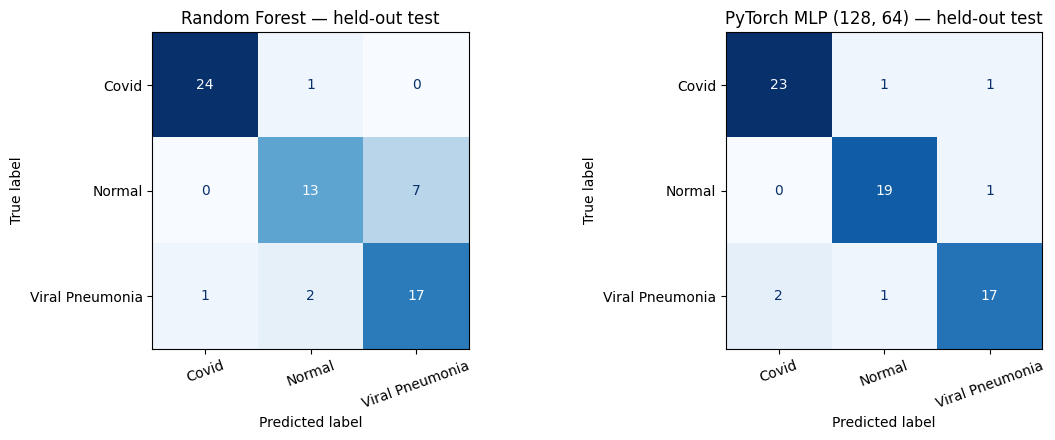

In [7]:
prediction_table = test_manifest[["relative_path", "class_name", "label"]].copy()
for name, predictions in test_predictions.items():
    print(f"\n{name} — held-out classification report")
    print(classification_report(
        y_test, predictions, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, digits=4, zero_division=0,
    ))
    report = classification_report(
        y_test, predictions, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    model_slug = "random_forest" if name == RF_NAME else "pytorch_mlp"
    pd.DataFrame(report).transpose().to_csv(TABLE_DIR / f"{model_slug}_classification_report.csv")
    prediction_table[f"{model_slug}_prediction"] = [CLASS_NAMES[index] for index in predictions]
prediction_table.to_csv(TABLE_DIR / "test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, test_predictions[name], labels=range(len(CLASS_NAMES))),
        display_labels=CLASS_NAMES,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} — held-out test")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

### A.5 — Visualise and explain the results

The brief's A.3 explicitly specifies two ML baselines. Accordingly, this Part A figure
compares those two models. The combined chart including CNN variants belongs to the
later comparison section after the CNN experiments have been implemented.

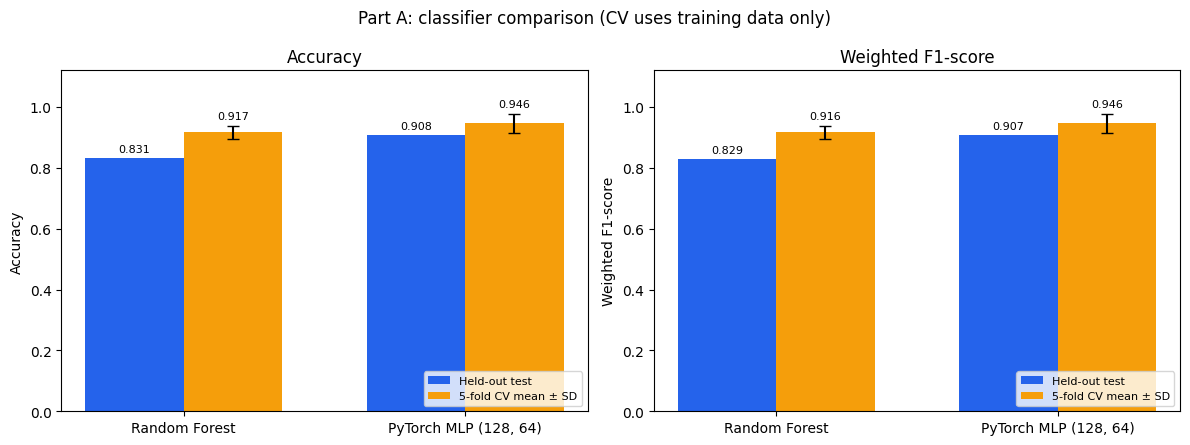

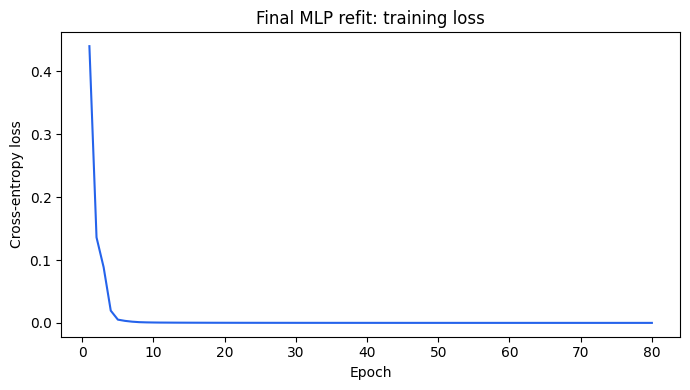

**Selected baseline: PyTorch MLP (128, 64).** Its mean five-fold CV accuracy is 0.946 ± 0.032, with mean weighted F1 0.946. The mean CV accuracy gap over Random Forest is 0.029. On the 65 unique held-out test images, its accuracy is 0.908 and weighted F1 is 0.907. One test error changes accuracy by approximately 1.54 percentage points.

A plausible explanation is that standardisation and dense layers learn useful nonlinear combinations of pixel intensities that the individual tree splits capture less efficiently. This is an interpretation, not a proven causal result. Fold variability and class-specific errors should be considered alongside the mean scores; these runs do not establish statistical significance. The test ordering may differ from CV ordering. A CNN can next be compared on the same clean image split to investigate learning spatial features.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(MODEL_NAMES))
width = 0.35
for ax, metric, title in zip(
    axes, ["accuracy", "weighted_f1"], ["Accuracy", "Weighted F1-score"]
):
    test_bars = ax.bar(positions - width / 2, comparison[f"test_{metric}"], width,
                       label="Held-out test", color="#2563eb")
    cv_bars = ax.bar(positions + width / 2, comparison[f"cv_{metric}_mean"], width,
                     yerr=comparison[f"cv_{metric}_std"], capsize=4,
                     label="5-fold CV mean ± SD", color="#f59e0b")
    ax.bar_label(test_bars, fmt="%.3f", padding=3, fontsize=8)
    ax.bar_label(cv_bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set(xticks=positions, xticklabels=MODEL_NAMES, ylim=(0, 1.12), ylabel=title, title=title)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Part A: classifier comparison (CV uses training data only)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mlp_history["epoch"], mlp_history["train_loss"], color="#2563eb")
ax.set(title="Final MLP refit: training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mlp_training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

best = comparison.loc[selected_baseline]
runner_up = ranked_cv.index[1]
cv_gap = best["cv_accuracy_mean"] - comparison.loc[runner_up, "cv_accuracy_mean"]
display(Markdown(
    f"**Selected baseline: {selected_baseline}.** Its mean five-fold CV accuracy is "
    f"{best['cv_accuracy_mean']:.3f} ± {best['cv_accuracy_std']:.3f}, with mean weighted "
    f"F1 {best['cv_weighted_f1_mean']:.3f}. The mean CV accuracy gap over {runner_up} is "
    f"{cv_gap:.3f}. On the {len(y_test)} unique held-out test images, its accuracy is "
    f"{best['test_accuracy']:.3f} and weighted F1 is {best['test_weighted_f1']:.3f}. "
    f"One test error changes accuracy by approximately {100 / len(y_test):.2f} percentage points."
))
if selected_baseline == RF_NAME:
    explanation = (
        "A plausible explanation is that an ensemble of trees handles this small, high-dimensional "
        "dataset more reliably than optimising a dense network. Correlated pixel features and "
        "limited examples can make MLP generalisation difficult."
    )
else:
    explanation = (
        "A plausible explanation is that standardisation and dense layers learn useful nonlinear "
        "combinations of pixel intensities that the individual tree splits capture less efficiently."
    )
display(Markdown(
    explanation + " This is an interpretation, not a proven causal result. Fold variability and "
    "class-specific errors should be considered alongside the mean scores; these runs do not "
    "establish statistical significance. The test ordering may differ from CV ordering. "
    "A CNN can next be compared on the same clean image split to investigate learning spatial features."
))

### Save Part A reproducibility artifacts

Save the original/clean split audit, shared fold assignments, full fold scores, test
predictions, comparison tables, plots, final scaler, RF estimator, MLP state dictionary,
training loss history, settings, and runtime versions. The clean manifest can be reused
by the later CNN experiments to keep the test set consistent. Learned parameters and
local runtime paths are stored as local artifacts; no Git commit or push is performed here.

In [9]:
joblib.dump(final_scaler, MODEL_DIR / "standard_scaler.joblib")
joblib.dump(final_models[RF_NAME], MODEL_DIR / "random_forest.joblib")
torch.save({
    "state_dict": {key: value.detach().cpu() for key, value in final_models[MLP_NAME].state_dict().items()},
    "input_dim": X_train.shape[1],
    "hidden_dims": list(MLP_HIDDEN_DIMS),
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "image_size": list(IMAGE_SIZE),
    "color_mode": "L",
    "resize_interpolation": "bilinear",
    "pixel_divisor": 255.0,
    "scaler_file": "standard_scaler.joblib",
}, MODEL_DIR / "pytorch_mlp.pt")
mlp_history.to_csv(TABLE_DIR / "mlp_training_history.csv", index=False)

experiment_config = {
    "seed": SEED,
    "image_size": list(IMAGE_SIZE),
    "color_mode": "L",
    "class_to_index": CLASS_TO_INDEX,
    "n_folds": N_FOLDS,
    "random_forest_trees": RF_TREES,
    "mlp_hidden_dims": list(MLP_HIDDEN_DIMS),
    "mlp_epochs": MLP_EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "original_train_samples": int(raw_manifest["split"].eq("train").sum()),
    "original_test_samples": int(raw_manifest["split"].eq("test").sum()),
    "clean_train_samples": len(y_train),
    "clean_test_samples": len(y_test),
    "selection_rule": "mean CV accuracy, then mean CV weighted F1",
    "selected_baseline": selected_baseline,
    "data_root_relative": DATA_DIR.relative_to(PROJECT_ROOT).as_posix(),
}
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(experiment_config, indent=2), encoding="utf-8")
(OUTPUT_DIR / "runtime.json").write_text(json.dumps(runtime_info, indent=2), encoding="utf-8")
print(f"Saved tables: {TABLE_DIR}")
print(f"Saved figures: {FIGURE_DIR}")
print(f"Saved models: {MODEL_DIR}")
print("Part A complete. CNN development and Part E are not implemented in this notebook.")

Saved tables: D:\PortfolioTask3\artifacts\part_a\tables
Saved figures: D:\PortfolioTask3\artifacts\part_a\figures
Saved models: D:\PortfolioTask3\artifacts\part_a\models
Part A complete. CNN development and Part E are not implemented in this notebook.


<a id="part-b"></a>
## Part B - Deep Learning: CNN for Image Classification

**Status: outline only. No CNN is built or trained yet.**

Extend the same experiment from flattened-pixel baselines to learned spatial features.
Reuse `clean_image_manifest.csv`, `CLASS_NAMES`, and `CLASS_TO_INDEX` from Part A so
all models are evaluated on the same 65-image test set. Read images from their clean
manifest paths rather than from the flattened or StandardScaler-transformed ML arrays.
Keep the test set held out during CNN architecture and hyperparameter selection.

### B.1 - Load and prepare image data

*Planned implementation:*

- Build PyTorch image datasets and loaders from the cleaned train/test manifests.
- Create a stratified validation subset from training data only.
- Define image dimensions, channel handling, tensor conversion, and pixel normalisation.
- Report class counts and class balance for train, validation, and test.
- Apply any imbalance experiment or augmentation to training data only, documenting it.

### B.2 - Build and configure CNN variants

*Planned implementation:*

- Define a PyTorch CNN with 32- and 64-filter convolutional blocks and max pooling;
  consider the recommended optional 128-filter block.
- Compare at least two configurations with documented Dense/Dropout settings.
- Configure Adam or AdamW and cross-entropy loss; inspect architecture and parameter counts.

### B.3 - Train and validate the CNNs

*Planned implementation:*

- Train on the verified CUDA device with recorded seeds and batch-size experiments.
- Monitor training and validation accuracy/loss.
- Use validation-based early stopping, restore the best weights, and reduce learning rate
  when validation loss plateaus.
- Select the CNN configuration using validation results without tuning on the test set.

### B.4 - Evaluate CNNs and compare with Part A

*Planned implementation:*

- Report test loss, accuracy, and per-class precision/recall/F1 for each CNN variant.
- Plot confusion matrices, learning curves, and sample predictions with true labels.
- Compare both CNN variants with the saved Part A baseline results on the same test split.
- Explain performance differences, overfitting, and the effect of architecture choices.

### B.5 - Save trained models and training histories

*Planned implementation:*

- Save model weights, architecture/preprocessing configuration, label mapping, and history.
- Save figures and evaluation tables for the report and later final comparison.
- Resolve the brief's `.h5` deliverable with the PyTorch model format when implementing
  this step; no CNN model export is performed in the current Part A implementation.

<a id="method-references"></a>
## Method references

- [PyTorch CUDA availability](https://docs.pytorch.org/docs/stable/generated/torch.cuda.is_available.html)
- [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html)
- [scikit-learn: data leakage and preprocessing](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [scikit-learn: RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

The assignment PDF is available in `docs/`. The implemented code covers its unmarked
Part A requirements; Part B follows the CNN direction and remains planned. Part E is excluded.